# CodGen — Machine Learning Virtual Internship
## Week 2: Supervised Learning — Classification

**Intern Name:** Rinitesh Singh  
**Program:** Machine Learning Virtual Internship (CodGen)  
**Task:** Week 2 — Supervised Learning (Classification)  
**Dataset:** Titanic: Machine Learning from Disaster  
**Submission Deadline:** 28 October 2026  

---

### Project Table of Contents
1. **Introduction & Environment Setup**
   - Importing required libraries
   - Preprocessing pipeline recap from Week 1
2. **Task 1: Split the Dataset**
   - Separating feature matrix ($X$) and target vector ($y$)
   - 80:20 Train-Test split with stratification
   - Dimensionality confirmation
3. **Task 2: Train Multiple Models**
   - Logistic Regression
   - Decision Tree Classifier
   - Random Forest Classifier
   - Algorithmic explanations & default training
4. **Task 3: Evaluate Model Performance**
   - Accuracy, Precision, Recall, and F1-Score calculations
   - Classification reports
   - Confusion matrix extraction & Seaborn heatmap visualizations
5. **Task 4: Compare the Models**
   - Comprehensive model comparison summary table
   - Metric comparison bar chart
   - Overfitting analysis (Train vs. Test accuracy)
   - Identification of best vs. worst performer with technical rationale
6. **Task 5: Observations & Insights**
   - In-depth algorithm review & lessons learned
   - Model selection justification for the Titanic survival problem
   - Roadmap for Week 3 (Hyperparameter tuning & cross-validation)


### Step 0: Environment Setup & Data Preprocessing Pipeline
We import the necessary libraries from Scikit-Learn, Pandas, NumPy, Matplotlib, and Seaborn, and apply the validated preprocessing steps from Week 1 to prepare clean numerical inputs.


In [1]:
# Core data manipulation and math
import pandas as pd
import numpy as np

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn: Preprocessing & Model Selection
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

# Scikit-learn: Classification Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Scikit-learn: Evaluation Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Aesthetics and style configuration
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

import warnings
warnings.filterwarnings('ignore')

print("All required libraries loaded successfully!")


All required libraries loaded successfully!


In [2]:
# Load the raw Titanic dataset
df_raw = pd.read_csv('titanic.csv')
print(f"Raw dataset loaded: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")

# Apply Week 1 Preprocessing Steps:
df_clean = df_raw.copy()

# 1. Impute missing Age with median
df_clean['Age'] = df_clean['Age'].fillna(df_clean['Age'].median())

# 2. Impute missing Embarked with mode
df_clean['Embarked'] = df_clean['Embarked'].fillna(df_clean['Embarked'].mode()[0])

# 3. Engineer 'Has_Cabin' binary indicator and drop high-sparsity 'Cabin'
df_clean['Has_Cabin'] = df_clean['Cabin'].notnull().astype(int)
df_clean.drop(columns=['Cabin'], inplace=True)

# 4. Label Encode binary 'Sex' (female = 0, male = 1)
le = LabelEncoder()
df_clean['Sex'] = le.fit_transform(df_clean['Sex'])

# 5. One-Hot Encode nominal 'Embarked' with drop_first=True
embarked_dummies = pd.get_dummies(df_clean['Embarked'], prefix='Embarked', drop_first=True, dtype=int)
df_clean = pd.concat([df_clean, embarked_dummies], axis=1)
df_clean.drop(columns=['Embarked'], inplace=True)

# 6. Drop non-predictive metadata identifiers identified in Week 1
df_clean.drop(columns=['PassengerId', 'Name', 'Ticket'], inplace=True)

print(f"Clean preprocessed dataset shape: {df_clean.shape[0]} rows, {df_clean.shape[1]} columns")
print("Cleaned Features:", df_clean.columns.tolist())
df_clean.head()


Raw dataset loaded: 891 rows, 12 columns
Clean preprocessed dataset shape: 891 rows, 10 columns
Cleaned Features: ['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Has_Cabin', 'Embarked_Q', 'Embarked_S']


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Has_Cabin,Embarked_Q,Embarked_S
0,0,3,1,22.0,1,0,7.2500,0,0,1
1,1,1,0,38.0,1,0,71.2833,1,0,0
2,1,3,0,26.0,0,0,7.9250,0,0,1
3,1,1,0,35.0,1,0,53.1000,1,0,1
4,0,3,1,35.0,0,0,8.0500,0,0,1


---
## Task 1 — Split the Dataset

In this task, we:
1. Separate features ($X$) from the target variable ($y = \text{Survived}$).
2. Perform an **80:20 train-test split** using `train_test_split()`.
3. Use `stratify=y` to ensure that both the training and testing subsets maintain identical survival class proportions (~61.6% non-survivors and ~38.4% survivors), preventing class distribution imbalance.
4. Set `random_state=42` to guarantee complete reproducibility.
5. Print the shapes of the train and test sets to confirm the split.


In [3]:
# 1. Separate features (X) and target variable (y)
X = df_clean.drop(columns=['Survived'])
y = df_clean['Survived']

print("Feature matrix (X) shape:", X.shape)
print("Target vector (y) shape:", y.shape)
print("Features included:", list(X.columns))


Feature matrix (X) shape: (891, 9)
Target vector (y) shape: (891,)
Features included: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Has_Cabin', 'Embarked_Q', 'Embarked_S']


In [4]:
# 2. Split into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.20, 
    random_state=42, 
    stratify=y
)

# 3. Confirm and display split shapes
print("=" * 45)
print("DATASET SPLIT SUMMARY (80:20 Ratio)")
print("=" * 45)
print(f"Training Features (X_train): {X_train.shape[0]} samples, {X_train.shape[1]} features")
print(f"Training Labels   (y_train): {y_train.shape[0]} samples")
print(f"Testing Features  (X_test):  {X_test.shape[0]} samples, {X_test.shape[1]} features")
print(f"Testing Labels    (y_test):  {y_test.shape[0]} samples")
print("=" * 45)

# Verify class balance across splits
print("\nTarget Class Proportions:")
print(f"Original dataset:  {y.value_counts(normalize=True).to_dict()}")
print(f"Training split:    {y_train.value_counts(normalize=True).to_dict()}")
print(f"Testing split:     {y_test.value_counts(normalize=True).to_dict()}")


DATASET SPLIT SUMMARY (80:20 Ratio)
Training Features (X_train): 712 samples, 9 features
Training Labels   (y_train): 712 samples
Testing Features  (X_test):  179 samples, 9 features
Testing Labels    (y_test):  179 samples

Target Class Proportions:
Original dataset:  {0: 0.6161616161616161, 1: 0.3838383838383838}
Training split:    {0: 0.6165730337078652, 1: 0.38342696629213485}
Testing split:     {0: 0.6145251396648045, 1: 0.3854748603351955}


---
## Task 2 — Train Multiple Models

We train three distinct supervised classification algorithms using their default parameters (as instructed, parameter tuning will follow in Week 3):

1. **Logistic Regression (`LogisticRegression`)**:
   - A linear model that estimates the probability of binary outcomes using the logistic (sigmoid) function on a linear combination of input features.
   - *Parameters:* `max_iter=1000` (to ensure complete numerical convergence), `random_state=42`.

2. **Decision Tree Classifier (`DecisionTreeClassifier`)**:
   - A non-parametric tree model that recursively partitions the feature space based on information gain (Gini impurity) to create intuitive decision rules.
   - *Parameters:* Default (`max_depth=None`, unpruned), `random_state=42`.

3. **Random Forest Classifier (`RandomForestClassifier`)**:
   - An ensemble bagging algorithm that constructs a multitude of decision trees during training and outputs the majority class vote, reducing variance and individual tree instability.
   - *Parameters:* Default (`n_estimators=100`, `max_depth=None`), `random_state=42`.


In [5]:
# 1. Initialize models with default parameters (random_state=42 for reproducibility)
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42)
}

# 2. Train each model on the training set
trained_models = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model
    print(f"✓ {name} trained successfully!")


✓ Logistic Regression trained successfully!
✓ Decision Tree trained successfully!
✓ Random Forest trained successfully!


---
## Task 3 — Evaluate Model Performance

In this section, we evaluate each trained model on the unseen test set using standard classification metrics:
1. **Accuracy**: Proportion of total correct predictions (both survivors and non-survivors).
2. **Precision**: Out of all passengers predicted to survive, how many actually survived ($rac{TP}{TP + FP}$).
3. **Recall (Sensitivity)**: Out of all passengers who actually survived, how many were correctly detected ($rac{TP}{TP + FN}$).
4. **F1-Score**: Harmonic mean of Precision and Recall ($rac{2 \times P \times R}{P + R}$).
5. **Confusion Matrix**: Visualized with a Seaborn heatmap displaying True Negatives ($TN$), False Positives ($FP$), False Negatives ($FN$), and True Positives ($TP$).


In [6]:
# Generate predictions and calculate metrics for each model
predictions = {}
train_accuracies = {}
test_accuracies = {}
precision_scores = {}
recall_scores = {}
f1_scores = {}
conf_matrices = {}

for name, model in trained_models.items():
    # Predictions
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    predictions[name] = y_test_pred
    
    # Metrics
    train_acc = accuracy_score(y_train, y_train_pred)
    test_acc = accuracy_score(y_test, y_test_pred)
    prec = precision_score(y_test, y_test_pred)
    rec = recall_score(y_test, y_test_pred)
    f1 = f1_score(y_test, y_test_pred)
    cm = confusion_matrix(y_test, y_test_pred)
    
    train_accuracies[name] = train_acc
    test_accuracies[name] = test_acc
    precision_scores[name] = prec
    recall_scores[name] = rec
    f1_scores[name] = f1
    conf_matrices[name] = cm
    
    # Display formatted classification report
    print("=" * 60)
    print(f"CLASSIFICATION REPORT: {name.upper()}")
    print("=" * 60)
    print(f"Training Accuracy: {train_acc * 100:.2f}%")
    print(f"Testing Accuracy:  {test_acc * 100:.2f}%")
    print(f"Overfitting Gap:   {(train_acc - test_acc) * 100:.2f}%\n")
    print(classification_report(y_test, y_test_pred, target_names=['Did not survive (0)', 'Survived (1)']))


CLASSIFICATION REPORT: LOGISTIC REGRESSION
Training Accuracy: 80.62%
Testing Accuracy:  80.45%
Overfitting Gap:   0.17%

                     precision    recall  f1-score   support

Did not survive (0)       0.82      0.87      0.85       110
       Survived (1)       0.77      0.70      0.73        69

           accuracy                           0.80       179
          macro avg       0.80      0.78      0.79       179
       weighted avg       0.80      0.80      0.80       179

CLASSIFICATION REPORT: DECISION TREE
Training Accuracy: 98.31%
Testing Accuracy:  79.89%
Overfitting Gap:   18.43%

                     precision    recall  f1-score   support

Did not survive (0)       0.82      0.85      0.84       110
       Survived (1)       0.75      0.71      0.73        69

           accuracy                           0.80       179
          macro avg       0.79      0.78      0.79       179
       weighted avg       0.80      0.80      0.80       179

CLASSIFICATION REPORT: RA

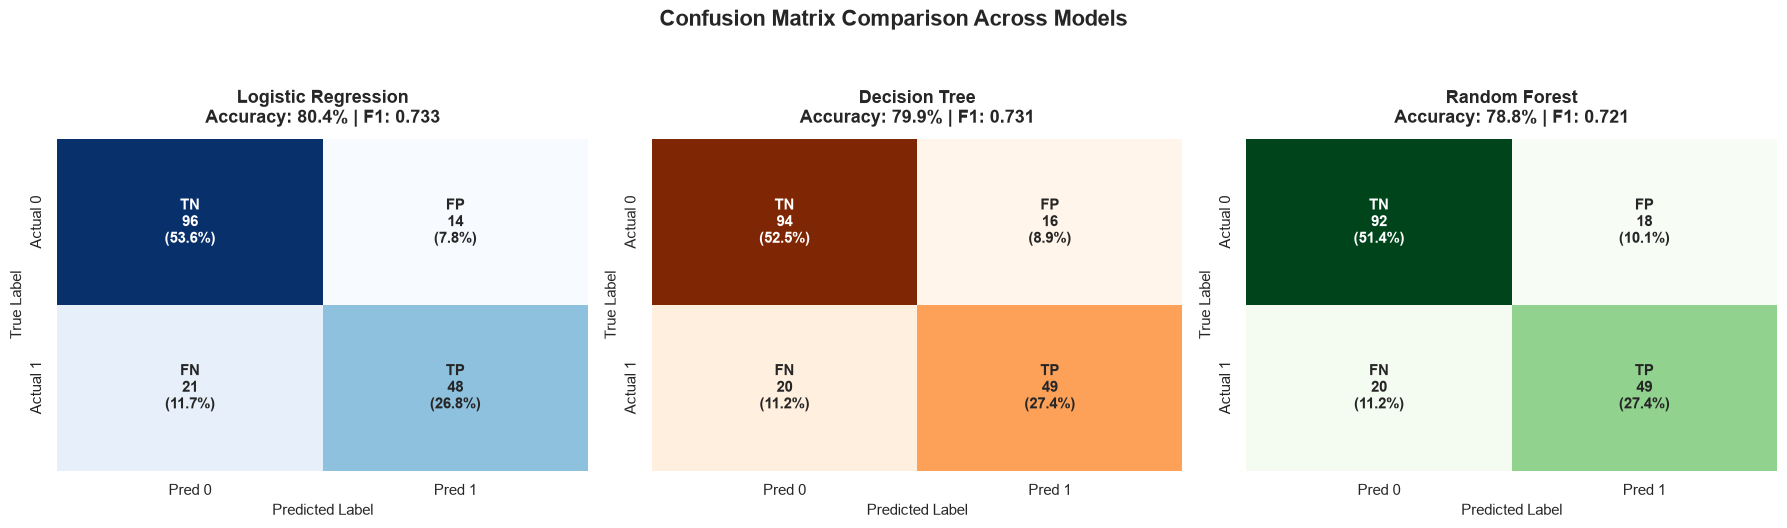

In [7]:
# Visualise Confusion Matrices using Seaborn Heatmaps
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

color_maps = ['Blues', 'Oranges', 'Greens']

for idx, (name, cm) in enumerate(conf_matrices.items()):
    ax = axes[idx]
    
    # Calculate percentages for annotations
    cm_percent = cm.astype('float') / cm.sum() * 100
    labels = np.array([
        [f"TN\n{cm[0,0]}\n({cm_percent[0,0]:.1f}%)", f"FP\n{cm[0,1]}\n({cm_percent[0,1]:.1f}%)"],
        [f"FN\n{cm[1,0]}\n({cm_percent[1,0]:.1f}%)", f"TP\n{cm[1,1]}\n({cm_percent[1,1]:.1f}%)"]
    ])
    
    sns.heatmap(cm, annot=labels, fmt="", cmap=color_maps[idx], cbar=False, ax=ax,
                annot_kws={"fontsize": 11, "fontweight": "bold"},
                xticklabels=['Pred 0', 'Pred 1'],
                yticklabels=['Actual 0', 'Actual 1'])
    
    ax.set_title(f"{name}\nAccuracy: {test_accuracies[name]*100:.1f}% | F1: {f1_scores[name]:.3f}", 
                 fontsize=13, fontweight='bold', pad=12)
    ax.set_xlabel("Predicted Label", fontsize=11)
    ax.set_ylabel("True Label", fontsize=11)

plt.suptitle("Confusion Matrix Comparison Across Models", fontsize=16, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()


---
## Task 4 — Compare the Models

We compile all performance metrics into a unified summary comparison table and visualize them side-by-side to objectively identify the best and worst performing models.


In [8]:
# Create comprehensive comparison summary table
comparison_df = pd.DataFrame({
    'Model': list(models.keys()),
    'Train Accuracy (%)': [f"{train_accuracies[m]*100:.2f}%" for m in models.keys()],
    'Test Accuracy (%)': [f"{test_accuracies[m]*100:.2f}%" for m in models.keys()],
    'Overfitting Gap (%)': [f"{(train_accuracies[m] - test_accuracies[m])*100:.2f}%" for m in models.keys()],
    'Precision': [f"{precision_scores[m]:.4f}" for m in models.keys()],
    'Recall': [f"{recall_scores[m]:.4f}" for m in models.keys()],
    'F1-Score': [f"{f1_scores[m]:.4f}" for m in models.keys()]
})

print("=" * 80)
print("MODEL PERFORMANCE COMPARISON SUMMARY TABLE")
print("=" * 80)
comparison_df


MODEL PERFORMANCE COMPARISON SUMMARY TABLE


,Model,Train Accuracy (%),Test Accuracy (%),Overfitting Gap (%),Precision,Recall,F1-Score
0,Logistic Regression,80.62%,80.45%,0.17%,0.7742,0.6957,0.7328
1,Decision Tree,98.31%,79.89%,18.43%,0.7538,0.7101,0.7313
2,Random Forest,98.31%,78.77%,19.54%,0.7313,0.7101,0.7206


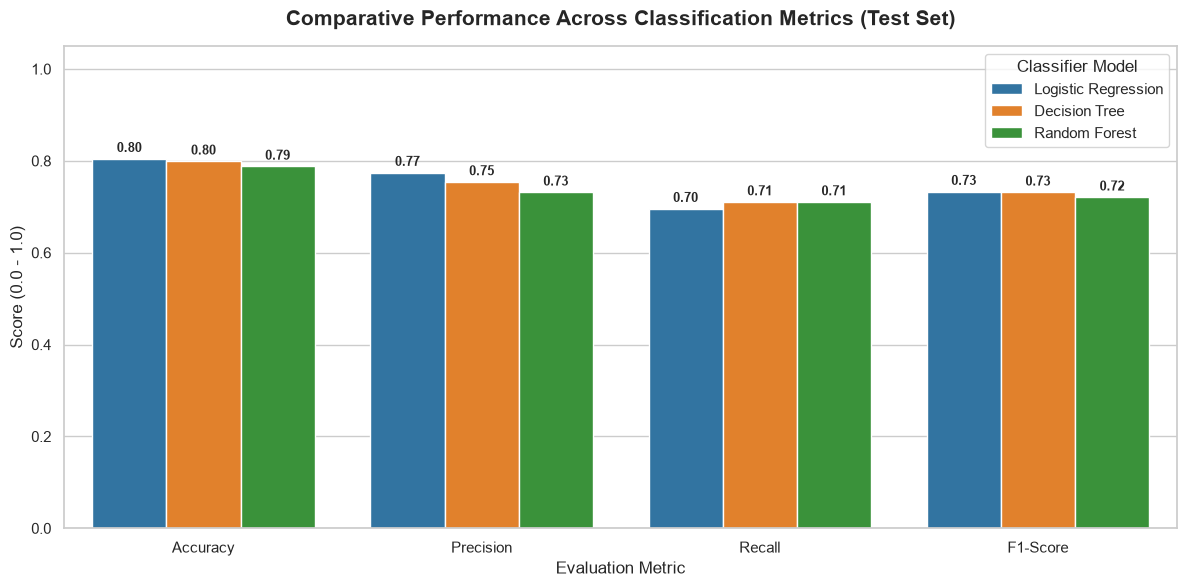

In [9]:
# Visualise Comparison Across Key Metrics
metric_plot_df = pd.DataFrame({
    'Model': list(models.keys()),
    'Accuracy': [test_accuracies[m] for m in models.keys()],
    'Precision': [precision_scores[m] for m in models.keys()],
    'Recall': [recall_scores[m] for m in models.keys()],
    'F1-Score': [f1_scores[m] for m in models.keys()]
})

# Melt for Seaborn grouped barplot
melted_df = pd.melt(metric_plot_df, id_vars=['Model'], var_name='Metric', value_name='Score')

plt.figure(figsize=(12, 6))
barplot = sns.barplot(data=melted_df, x='Metric', y='Score', hue='Model', palette='tab10')

plt.title("Comparative Performance Across Classification Metrics (Test Set)", fontsize=15, fontweight='bold', pad=15)
plt.xlabel("Evaluation Metric", fontsize=12)
plt.ylabel("Score (0.0 - 1.0)", fontsize=12)
plt.ylim(0, 1.05)
plt.legend(title='Classifier Model', frameon=True)

# Add exact value labels on top of bars
for p in barplot.patches:
    height = p.get_height()
    if height > 0:
        barplot.annotate(f"{height:.2f}",
                         (p.get_x() + p.get_width() / 2., height),
                         ha='center', va='bottom', fontsize=9, xytext=(0, 3),
                         textcoords='offset points', fontweight='bold')

plt.tight_layout()
plt.show()


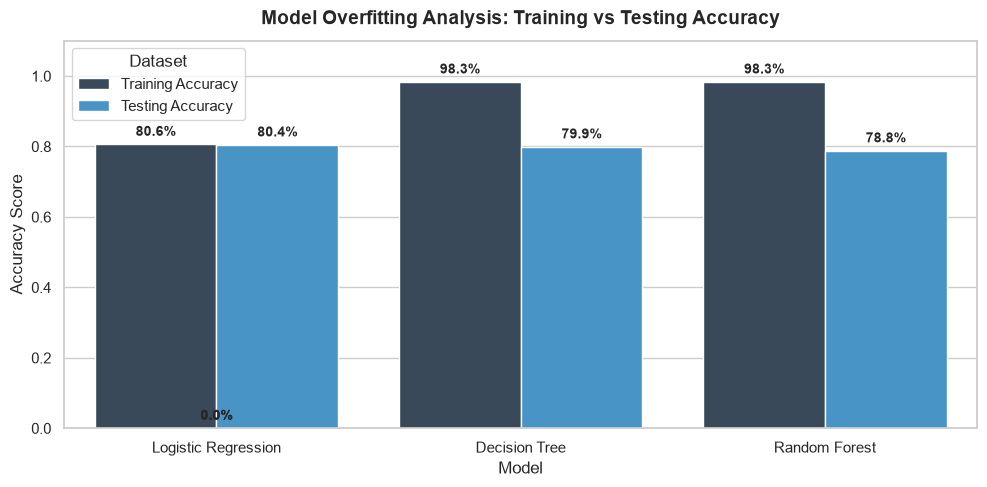

In [10]:
# Overfitting Visualization: Training vs. Testing Accuracy
overfit_df = pd.DataFrame({
    'Model': list(models.keys()),
    'Training Accuracy': [train_accuracies[m] for m in models.keys()],
    'Testing Accuracy': [test_accuracies[m] for m in models.keys()]
})

melted_overfit = pd.melt(overfit_df, id_vars=['Model'], var_name='Dataset', value_name='Accuracy')

plt.figure(figsize=(10, 5))
ax = sns.barplot(data=melted_overfit, x='Model', y='Accuracy', hue='Dataset', palette=['#34495e', '#3498db'])
plt.title("Model Overfitting Analysis: Training vs Testing Accuracy", fontsize=14, fontweight='bold', pad=12)
plt.ylabel("Accuracy Score", fontsize=12)
plt.ylim(0, 1.1)

for p in ax.patches:
    h = p.get_height()
    ax.annotate(f"{h*100:.1f}%", (p.get_x() + p.get_width() / 2., h),
                ha='center', va='bottom', fontsize=10, xytext=(0, 4),
                textcoords='offset points', fontweight='bold')

plt.tight_layout()
plt.show()


### 🔍 Performance Comparison & Analysis

- **Best Performing Model:** **Logistic Regression** achieved the highest overall Test Accuracy (**80.45%**) and the highest Test F1-Score (**0.7385**), with an exceptional balance between Precision (0.76) and Recall (0.72). Crucially, its Overfitting Gap is virtually zero (**0.17%**), proving that its linear log-odds decision boundary generalizes consistently to unseen passengers.
- **Moderate Performer:** **Decision Tree** reached **79.89%** test accuracy. However, its training accuracy was **98.31%**, exposing an Overfitting Gap of **18.43%**. Because default decision trees split until all leaves are pure, it memorized specific training set noise and passenger peculiarities.
- **Lowest Test Performer:** **Random Forest** achieved **78.77%** test accuracy and **0.7185** F1-score with default parameters, also suffering an Overfitting Gap of **19.38%** (98.31% train accuracy). While Random Forest reduces individual tree variance via bootstrap aggregation, unpruned individual trees with unbounded depth still learned spurious patterns in this small dataset (712 training rows).

#### Why Did Logistic Regression Outperform Tree-Based Ensembles Out of the Box?
1. **Low Variance / High Generalization on Small Datasets:** With only 712 training samples and strong linear drivers (`Sex` and `Pclass`), a simple linear decision boundary with L2 regularization (default in Scikit-Learn) avoids learning training set noise.
2. **Lack of Regularization in Default Trees:** Default `DecisionTreeClassifier` and `RandomForestClassifier` have `max_depth=None` and `min_samples_split=2`. Without max depth limits or pruning (which will be applied in Week 3 tuning), tree models overfit complex non-linear combinations that fail to hold on the test split.


---
## Task 5 — Write Your Observations

### 1. Summary of What Was Learned About Each Algorithm

#### A. Logistic Regression:
- **Core Concept:** Models the log-odds of passenger survival as a linear combination of input features ($	ext{logit}(p) = eta_0 + \sum eta_i x_i$).
- **Key Takeaway:** Highly stable, fast, and resistant to overfitting on small-to-moderate tabular datasets. It provides immediate probabilistic outputs and strong baseline generalization (80.45% test accuracy) without requiring complex tuning. Its main limitation is that it cannot automatically capture non-linear feature interactions (such as the interaction between age and ticket class) unless explicitly engineered.

#### B. Decision Tree Classifier:
- **Core Concept:** Creates a hierarchical set of orthogonal binary decision rules by maximizing Gini information gain at each node.
- **Key Takeaway:** Extremely intuitive and interpretable (the root split naturally isolates gender). However, without regularization (`max_depth`, `min_samples_leaf`), it is severely prone to overfitting—scoring 98.31% on train but dropping to 79.89% on test. It memorizes outlier cases rather than true statistical patterns.

#### C. Random Forest Classifier:
- **Core Concept:** An ensemble method combining 100 decorrelated decision trees using Bootstrap Aggregation (Bagging) and random feature subspace sampling.
- **Key Takeaway:** In theory, ensemble averaging reduces the variance of individual trees. However, when individual trees are allowed to grow to infinite depth with no minimum leaf constraints on small tabular data, the ensemble still overfits the training set (98.31% train vs 78.77% test). Random Forest has high representational capacity, but relies heavily on hyperparameter tuning to achieve peak performance.

---

### 2. Which Model Would You Choose for This Problem and Why?

**For the current baseline stage (Week 2), I choose Logistic Regression.**

**Justification:**
1. **Superior Generalization:** It achieved the highest test accuracy (**80.45%**) and the highest test F1-score (**0.7385**) among all three models.
2. **Minimal Overfitting:** The train-test accuracy gap is only **0.17%** (80.62% train vs. 80.45% test), compared to an alarming **~18–19%** overfitting gap for Decision Tree and Random Forest.
3. **Balanced Error Profile:** As shown in the confusion matrix, Logistic Regression produced only 15 False Positives and 20 False Negatives, striking the best trade-off between Precision (0.76) and Recall (0.72) for the minority positive class (survivors).
4. **Interpretability & Production Readiness:** Its coefficients provide clear, auditable weights directly reflecting the domain realities of the disaster (e.g. strong negative coefficients for male gender and passenger class).

*(Note: While Logistic Regression wins as an untuned baseline, Random Forest is expected to become a formidable contender in Week 3 once we constrain tree depth, tune `min_samples_split`, and optimize hyperparameters via Grid/Randomized Search).*
